In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)  # show all columns, don't hide any
sns.set_style("whitegrid")

In [2]:
cols = [
    "age", "sex", "on_thyroxine", "query_on_thyroxine", "on_antithyroid_medication",
    "sick", "pregnant", "thyroid_surgery", "I131_treatment", "query_hypothyroid",
    "query_hyperthyroid", "lithium", "goitre", "tumor", "hypopituitary", "psych",
    "TSH_measured", "TSH", "T3_measured", "T3", "TT4_measured", "TT4",
    "T4U_measured", "T4U", "FTI_measured", "FTI", "TBG_measured", "TBG",
    "referral_source", "class_raw",
]

df = pd.read_csv("../data/thyroid0387.data", header=None, names=cols, na_values="?")
print("Shape:", df.shape)

Shape: (9172, 30)


In [3]:
df.head()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,class_raw
0,29,F,f,f,f,f,f,f,f,t,f,f,f,f,f,f,t,0.3,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,other,-[840801013]
1,29,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.6,t,1.9,t,128.0,f,NaN,f,NaN,f,NaN,other,-[840801014]
2,41,F,f,f,f,f,f,f,f,f,t,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,11.0,other,-[840801042]
3,36,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,26.0,other,-[840803046]
4,32,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,36.0,other,S[840803047]


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9172 entries, 0 to 9171
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        9172 non-null   int64  
 1   sex                        8865 non-null   str    
 2   on_thyroxine               9172 non-null   str    
 3   query_on_thyroxine         9172 non-null   str    
 4   on_antithyroid_medication  9172 non-null   str    
 5   sick                       9172 non-null   str    
 6   pregnant                   9172 non-null   str    
 7   thyroid_surgery            9172 non-null   str    
 8   I131_treatment             9172 non-null   str    
 9   query_hypothyroid          9172 non-null   str    
 10  query_hyperthyroid         9172 non-null   str    
 11  lithium                    9172 non-null   str    
 12  goitre                     9172 non-null   str    
 13  tumor                      9172 non-null   str    
 14  hyp

In [5]:
missing = df.isna().mean().mul(100).round(2).sort_values(ascending=False)
missing[missing > 0]

TBG    96.19
T3     28.39
TSH     9.18
T4U     8.82
FTI     8.74
TT4     4.82
sex     3.35
dtype: float64

In [6]:
df["age"].describe()

count     9172.000000
mean        73.555822
std       1183.976718
min          1.000000
25%         37.000000
50%         55.000000
75%         68.000000
max      65526.000000
Name: age, dtype: float64

In [7]:
# remove the [patient_id] part, keep only the diagnosis code
df["code"] = df["class_raw"].str.replace(r"\[[0-9]+\]", "", regex=True)

def map_category(code):
    if code == "-":
        return "Negative"
    if code in ("A", "B", "C", "D"):
        return "Hyperthyroid"
    if code == "F":
        return "Primary Hypothyroid"
    if code == "G":
        return "Compensated Hypothyroid"
    return "Other Thyroid Condition"

df["target"] = df["code"].apply(map_category)
df["target"].value_counts()

target
Negative                   6771
Other Thyroid Condition    1627
Compensated Hypothyroid     359
Primary Hypothyroid         233
Hyperthyroid                182
Name: count, dtype: int64

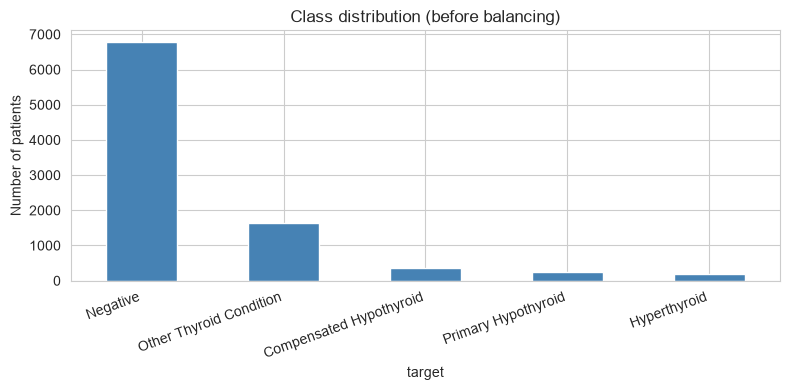

In [8]:
ax = df["target"].value_counts().plot(kind="bar", figsize=(8, 4), color="steelblue")
ax.set_title("Class distribution (before balancing)")
ax.set_ylabel("Number of patients")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()